STAGE 2 — FINAL HIDDEN TEST EVALUATION
Device: cuda
GPU: NVIDIA RTX A6000

Loading E23 checkpoint...
Checkpoint loaded.
Epoch: 8
Recorded validation mIoU: 0.5001583099365234

VERIFYING E23 VALIDATION PERFORMANCE


Evaluating val:   0%|          | 0/10 [00:00<?, ?it/s]

Recorded validation mIoU: 50.016%
Recomputed validation mIoU: 50.019%

Validation reproduction PASSED.

FINAL HIDDEN TEST EVALUATION — 100 TILES


Evaluating test:   0%|          | 0/13 [00:00<?, ?it/s]


FINAL TEST RESULTS
Overall Accuracy : 79.042%
Mean IoU         : 57.411%
Macro F1         : 70.111%

PER-CLASS TEST METRICS


,Class,IoU (%),F1 (%),Precision (%),Recall (%)
0,Tree,66.031,79.541,78.234,80.892
1,Shrub/Grass/Moss,34.861,51.699,45.942,59.105
2,Cropland,71.098,83.108,89.576,77.511
3,Built-up,57.396,72.932,70.849,75.142
4,Bare/Snow/Ice,23.144,37.588,54.366,28.724
5,Water/Wetland/Mangrove,91.935,95.798,96.783,94.833


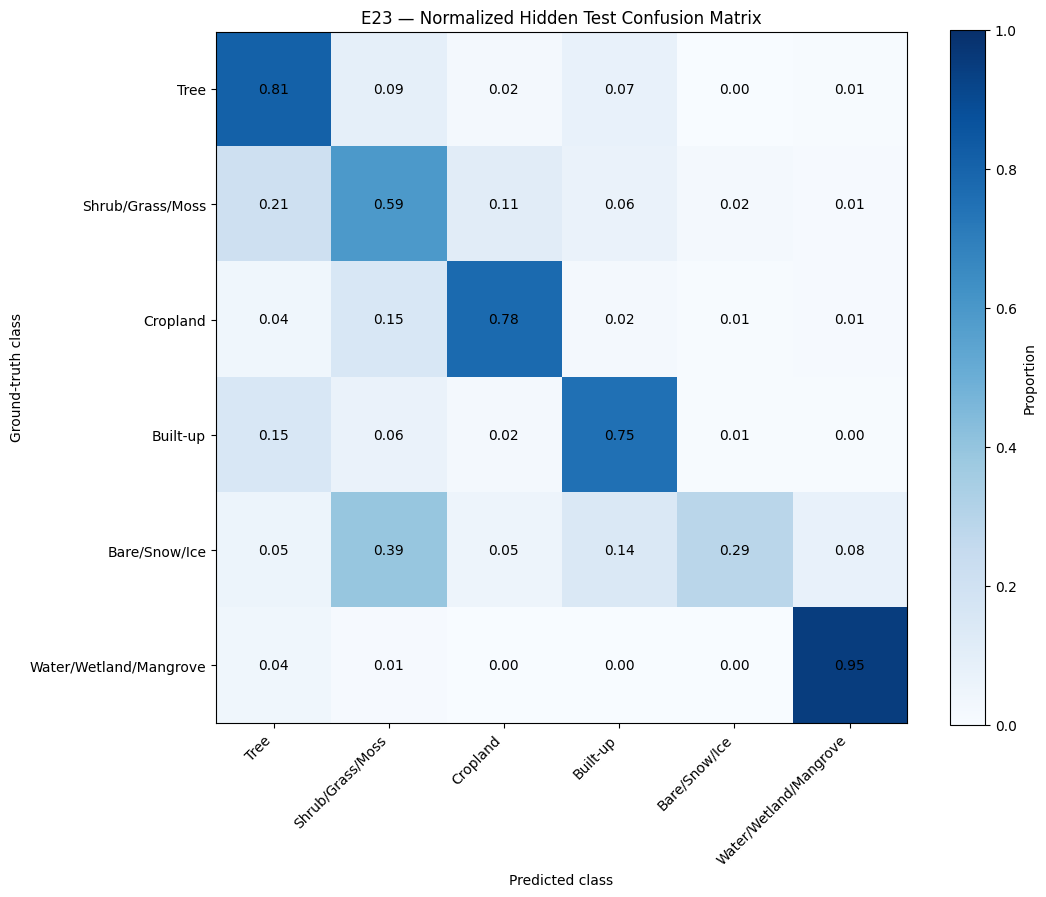


Generating test predictions for inspection...


Predicting test tiles:   0%|          | 0/100 [00:00<?, ?it/s]


Individual tile metrics saved.


,Tile,OA (%),mIoU (%),Macro F1 (%)
0,addis_ababa_01,64.777,18.601,25.947
1,addis_ababa_02,87.802,16.410,18.845
2,addis_ababa_03,72.827,27.230,36.594
3,addis_ababa_04,57.539,19.902,28.132
4,addis_ababa_05,81.682,21.186,28.042
5,addis_ababa_06,59.506,27.890,38.602
6,addis_ababa_07,80.103,28.672,36.027
7,addis_ababa_08,66.713,14.887,20.481
8,addis_ababa_09,44.275,17.264,26.938
9,addis_ababa_10,55.266,26.252,37.380



STAGE 2 COMPLETED
Model: E23 ResNet34 U-Net
Test tiles: 100
Overall Accuracy: 79.042%
Mean IoU: 57.411%
Macro F1: 70.111%

OUTPUT FILES:
all_test_ground_truths.npy (6.25 MB)
all_test_predictions.npy (6.25 MB)
individual_tile_metrics.csv (0.01 MB)
per_class_metrics.csv (0.00 MB)
test_confusion_matrix.npy (0.00 MB)
test_confusion_matrix.png (0.30 MB)
test_confusion_matrix_counts.csv (0.00 MB)
test_metrics.json (0.00 MB)
test_tile_names.json (0.00 MB)

Stage 2 evaluation finished.
Next: Stage 3 — Latitude/Longitude/Start Month Prototype.


In [3]:

# ================================================================
# STAGE 2 — FINAL HIDDEN TEST EVALUATION
# E23 ResNet34 U-Net | 100 Geographic Test Tiles
# ================================================================

import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from IPython.display import display, clear_output
import ipywidgets as widgets

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

PROJECT_DIR = Path("/home/jovyan/vault/LULC_Project")

DATA_DIR = PROJECT_DIR / "processed_dataset_unified"

CHECKPOINT_PATH = (
    PROJECT_DIR /
    "results/exp23_e21_targeted_finetune/checkpoints/best_exp23.pth"
)

OUTPUT_DIR = (
    PROJECT_DIR / "results/final_hidden_test_evaluation"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_CLASSES = 6
BATCH_SIZE = 8
IGNORE_INDEX = 255

CLASS_NAMES = [
    "Tree",
    "Shrub/Grass/Moss",
    "Cropland",
    "Built-up",
    "Bare/Snow/Ice",
    "Water/Wetland/Mangrove"
]

CLASS_COLORS = [
    "#26733B",
    "#B5A642",
    "#E6C84F",
    "#D94841",
    "#B7A99A",
    "#2878B5"
]

print("=" * 75)
print("STAGE 2 — FINAL HIDDEN TEST EVALUATION")
print("=" * 75)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert DATA_DIR.exists(), f"Dataset not found: {DATA_DIR}"
assert CHECKPOINT_PATH.exists(), f"Checkpoint not found: {CHECKPOINT_PATH}"

# ================================================================
# 2. DATASET
# ================================================================

class LULCDataset(Dataset):

    def __init__(self, root):

        self.root = Path(root)

        self.image_dir = self.root / "images"
        self.mask_dir = self.root / "masks"
        self.validity_dir = self.root / "validity"

        self.image_files = sorted(
            self.image_dir.glob("*.npy")
        )

        self.mask_files = sorted(
            self.mask_dir.glob("*.npy")
        )

        self.validity_files = sorted(
            self.validity_dir.glob("*.npy")
        )

        assert len(self.image_files) > 0, (
            f"No images found in {self.image_dir}"
        )

        assert (
            len(self.image_files) ==
            len(self.mask_files) ==
            len(self.validity_files)
        ), "Image, mask and validity file counts differ."

        assert (
            [p.stem for p in self.image_files] ==
            [p.stem for p in self.mask_files] ==
            [p.stem for p in self.validity_files]
        ), "Image, mask and validity filenames do not match."

    def __len__(self):
        return len(self.image_files)

    def load_input(self, idx):

        image = np.load(
            self.image_files[idx]
        ).astype(np.float32)

        validity = np.load(
            self.validity_files[idx]
        ).astype(np.float32)

        assert image.shape == (12, 2, 256, 256), (
            f"Unexpected image shape: {image.shape}"
        )

        assert validity.shape == image.shape, (
            f"Unexpected validity shape: {validity.shape}"
        )

        image = image.reshape(24, 256, 256)

        validity = validity.reshape(24, 256, 256)

        x = np.concatenate(
            [image, validity],
            axis=0
        )

        return torch.from_numpy(
            np.ascontiguousarray(x)
        )

    def load_ground_truth(self, idx):

        mask = np.load(
            self.mask_files[idx]
        ).astype(np.int64)

        assert mask.shape == (256, 256), (
            f"Unexpected mask shape: {mask.shape}"
        )

        return torch.from_numpy(mask)

    def __getitem__(self, idx):

        return (
            self.load_input(idx),
            self.load_ground_truth(idx)
        )


# ================================================================
# 3. MODEL ARCHITECTURE
# ================================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.block(x)


class BasicBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        channels,
        stride=1
    ):

        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(channels)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(channels)

        self.shortcut = nn.Sequential()

        if stride != 1 or in_channels != channels:

            self.shortcut = nn.Sequential(

                nn.Conv2d(
                    in_channels,
                    channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),

                nn.BatchNorm2d(channels)
            )

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        return self.relu(out)


class DecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.conv = DoubleConv(
            in_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat(
            [x, skip],
            dim=1
        )

        return self.conv(x)


class ResNet34UNet(nn.Module):

    def __init__(self, num_classes=6):

        super().__init__()

        self.input_projection = DoubleConv(
            48,
            32
        )

        self.conv1 = nn.Conv2d(
            48,
            64,
            kernel_size=7,
            stride=2,
            padding=3,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(64)

        self.relu = nn.ReLU(inplace=True)

        self.maxpool = nn.MaxPool2d(
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.in_channels = 64

        self.layer1 = self.make_layer(64, 3)
        self.layer2 = self.make_layer(128, 4, 2)
        self.layer3 = self.make_layer(256, 6, 2)
        self.layer4 = self.make_layer(512, 3, 2)

        self.decoder4 = DecoderBlock(768, 256)
        self.decoder3 = DecoderBlock(384, 128)
        self.decoder2 = DecoderBlock(192, 64)
        self.decoder1 = DecoderBlock(128, 64)
        self.decoder0 = DecoderBlock(96, 32)

        self.classifier = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )

    def make_layer(
        self,
        channels,
        blocks,
        stride=1
    ):

        layers = [
            BasicBlock(
                self.in_channels,
                channels,
                stride
            )
        ]

        self.in_channels = channels

        for _ in range(1, blocks):

            layers.append(
                BasicBlock(
                    channels,
                    channels
                )
            )

        return nn.Sequential(*layers)

    def forward(self, x):

        projected = self.input_projection(x)

        stem = self.relu(
            self.bn1(
                self.conv1(x)
            )
        )

        pooled = self.maxpool(stem)

        e1 = self.layer1(pooled)
        e2 = self.layer2(e1)
        e3 = self.layer3(e2)
        e4 = self.layer4(e3)

        d4 = self.decoder4(e4, e3)
        d3 = self.decoder3(d4, e2)
        d2 = self.decoder2(d3, e1)
        d1 = self.decoder1(d2, stem)
        d0 = self.decoder0(d1, projected)

        return self.classifier(d0)


# ================================================================
# 4. LOAD CHECKPOINT
# ================================================================

print("\nLoading E23 checkpoint...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = ResNet34UNet(
    num_classes=NUM_CLASSES
)

if "model_state_dict" in checkpoint:

    state_dict = checkpoint["model_state_dict"]

elif "state_dict" in checkpoint:

    state_dict = checkpoint["state_dict"]

else:

    raise RuntimeError(
        "Could not find model_state_dict or state_dict."
    )

model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("Checkpoint loaded.")
print("Epoch:", checkpoint.get("epoch"))
print("Recorded validation mIoU:",
      checkpoint.get("val_miou"))


# ================================================================
# 5. METRIC FUNCTIONS
# ================================================================

def calculate_metrics(confusion):

    conf = confusion.astype(np.float64)

    tp = np.diag(conf)

    actual = conf.sum(axis=1)

    predicted = conf.sum(axis=0)

    union = actual + predicted - tp

    iou = np.divide(
        tp,
        union,
        out=np.zeros_like(tp),
        where=union > 0
    )

    precision = np.divide(
        tp,
        predicted,
        out=np.zeros_like(tp),
        where=predicted > 0
    )

    recall = np.divide(
        tp,
        actual,
        out=np.zeros_like(tp),
        where=actual > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(tp),
        where=(precision + recall) > 0
    )

    oa = tp.sum() / max(conf.sum(), 1)

    return {
        "oa": float(oa),
        "miou": float(iou.mean()),
        "macro_f1": float(f1.mean()),
        "iou": iou,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }


# ================================================================
# 6. EVALUATION FUNCTION
# ================================================================

def evaluate_split(split_name):

    dataset = LULCDataset(
        DATA_DIR / split_name
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64
    )

    with torch.inference_mode():

        for images, masks in tqdm(
            loader,
            desc=f"Evaluating {split_name}"
        ):

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            logits = model(images)

            predictions = (
                logits.argmax(dim=1)
                .cpu()
                .numpy()
            )

            masks = masks.numpy()

            for pred, target in zip(
                predictions,
                masks
            ):

                valid = (
                    (target >= 0) &
                    (target < NUM_CLASSES)
                )

                indices = (
                    target[valid] * NUM_CLASSES +
                    pred[valid]
                )

                confusion += np.bincount(
                    indices,
                    minlength=NUM_CLASSES ** 2
                ).reshape(
                    NUM_CLASSES,
                    NUM_CLASSES
                )

    return confusion


# ================================================================
# 7. VALIDATION REPRODUCTION
# ================================================================

print("\n" + "=" * 75)
print("VERIFYING E23 VALIDATION PERFORMANCE")
print("=" * 75)

val_confusion = evaluate_split("val")

val_metrics = calculate_metrics(
    val_confusion
)

recorded_miou = float(
    checkpoint["val_miou"]
)

print(
    f"Recorded validation mIoU: "
    f"{recorded_miou * 100:.3f}%"
)

print(
    f"Recomputed validation mIoU: "
    f"{val_metrics['miou'] * 100:.3f}%"
)

if abs(
    val_metrics["miou"] - recorded_miou
) > 0.002:

    raise RuntimeError(
        "\nVALIDATION REPRODUCTION FAILED.\n"
        "The reconstructed architecture or evaluation protocol "
        "does not reproduce the checkpoint result. "
        "Hidden test evaluation has been stopped."
    )

print("\nValidation reproduction PASSED.")


# ================================================================
# 8. FINAL HIDDEN TEST EVALUATION
# ================================================================

print("\n" + "=" * 75)
print("FINAL HIDDEN TEST EVALUATION — 100 TILES")
print("=" * 75)

test_dataset = LULCDataset(
    DATA_DIR / "test"
)

assert len(test_dataset) == 100, (
    f"Expected 100 test tiles, found {len(test_dataset)}"
)

test_confusion = evaluate_split("test")

test_metrics = calculate_metrics(
    test_confusion
)

print("\n" + "=" * 75)
print("FINAL TEST RESULTS")
print("=" * 75)

print(
    f"Overall Accuracy : "
    f"{test_metrics['oa'] * 100:.3f}%"
)

print(
    f"Mean IoU         : "
    f"{test_metrics['miou'] * 100:.3f}%"
)

print(
    f"Macro F1         : "
    f"{test_metrics['macro_f1'] * 100:.3f}%"
)


# ================================================================
# 9. PER-CLASS METRICS
# ================================================================

rows = []

for i, class_name in enumerate(CLASS_NAMES):

    rows.append({

        "Class": class_name,

        "IoU (%)":
            test_metrics["iou"][i] * 100,

        "F1 (%)":
            test_metrics["f1"][i] * 100,

        "Precision (%)":
            test_metrics["precision"][i] * 100,

        "Recall (%)":
            test_metrics["recall"][i] * 100
    })

metrics_df = pd.DataFrame(rows)

print("\nPER-CLASS TEST METRICS")

display(
    metrics_df.round(3)
)


# ================================================================
# 10. SAVE METRICS
# ================================================================

summary = {

    "model": "E23 ResNet34 U-Net",

    "checkpoint": str(CHECKPOINT_PATH),

    "checkpoint_epoch": int(
        checkpoint.get("epoch", -1)
    ),

    "test_tiles": len(test_dataset),

    "overall_accuracy": test_metrics["oa"],

    "mean_iou": test_metrics["miou"],

    "macro_f1": test_metrics["macro_f1"],

    "per_class": rows
}

with open(
    OUTPUT_DIR / "test_metrics.json",
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

metrics_df.to_csv(
    OUTPUT_DIR / "per_class_metrics.csv",
    index=False
)

np.save(
    OUTPUT_DIR / "test_confusion_matrix.npy",
    test_confusion
)

pd.DataFrame(
    test_confusion,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUTPUT_DIR / "test_confusion_matrix_counts.csv"
)


# ================================================================
# 11. CONFUSION MATRIX VISUALIZATION
# ================================================================

row_sums = test_confusion.sum(
    axis=1,
    keepdims=True
)

normalized_confusion = np.divide(
    test_confusion,
    row_sums,
    out=np.zeros_like(
        test_confusion,
        dtype=np.float64
    ),
    where=row_sums != 0
)

fig, ax = plt.subplots(
    figsize=(11, 9)
)

im = ax.imshow(
    normalized_confusion,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))

ax.set_xticklabels(
    CLASS_NAMES,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(CLASS_NAMES)

ax.set_xlabel("Predicted class")
ax.set_ylabel("Ground-truth class")

ax.set_title(
    "E23 — Normalized Hidden Test Confusion Matrix"
)

for i in range(NUM_CLASSES):

    for j in range(NUM_CLASSES):

        ax.text(
            j,
            i,
            f"{normalized_confusion[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Proportion"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 12. GENERATE PREDICTIONS FOR ALL TEST TILES
# ================================================================

print("\nGenerating test predictions for inspection...")

all_predictions = []

all_ground_truths = []

all_tile_names = []

with torch.inference_mode():

    for idx in tqdm(
        range(len(test_dataset)),
        desc="Predicting test tiles"
    ):

        x = test_dataset.load_input(idx)

        logits = model(
            x.unsqueeze(0).to(DEVICE)
        )

        prediction = (
            logits.argmax(dim=1)[0]
            .cpu()
            .numpy()
            .astype(np.uint8)
        )

        ground_truth = (
            test_dataset.load_ground_truth(idx)
            .numpy()
            .astype(np.uint8)
        )

        all_predictions.append(prediction)

        all_ground_truths.append(ground_truth)

        all_tile_names.append(
            test_dataset.image_files[idx].stem
        )

all_predictions = np.stack(
    all_predictions
)

all_ground_truths = np.stack(
    all_ground_truths
)

np.save(
    OUTPUT_DIR / "all_test_predictions.npy",
    all_predictions
)

np.save(
    OUTPUT_DIR / "all_test_ground_truths.npy",
    all_ground_truths
)

with open(
    OUTPUT_DIR / "test_tile_names.json",
    "w"
) as f:

    json.dump(
        all_tile_names,
        f,
        indent=4
    )


# ================================================================
# 13. INDIVIDUAL TILE METRICS
# ================================================================

tile_rows = []

for idx in range(len(test_dataset)):

    pred = all_predictions[idx].astype(np.int64)

    target = all_ground_truths[idx].astype(np.int64)

    valid = (
        (target >= 0) &
        (target < NUM_CLASSES)
    )

    indices = (
        target[valid] * NUM_CLASSES +
        pred[valid]
    )

    tile_conf = np.bincount(
        indices,
        minlength=NUM_CLASSES ** 2
    ).reshape(
        NUM_CLASSES,
        NUM_CLASSES
    )

    tile_metrics = calculate_metrics(
        tile_conf
    )

    tile_rows.append({

        "Tile": all_tile_names[idx],

        "OA (%)":
            tile_metrics["oa"] * 100,

        "mIoU (%)":
            tile_metrics["miou"] * 100,

        "Macro F1 (%)":
            tile_metrics["macro_f1"] * 100
    })

tile_df = pd.DataFrame(tile_rows)

tile_df.to_csv(
    OUTPUT_DIR / "individual_tile_metrics.csv",
    index=False
)

print("\nIndividual tile metrics saved.")

display(
    tile_df.head(10).round(3)
)


# ================================================================
# 14. INTERACTIVE TEST TILE VIEWER
# ================================================================

def show_test_tile(idx):

    x = test_dataset.load_input(idx).numpy()

    prediction = all_predictions[idx]

    ground_truth = all_ground_truths[idx].astype(
        np.int64
    )

    valid = (
        (ground_truth >= 0) &
        (ground_truth < NUM_CLASSES)
    )

    tile_conf = np.bincount(
        ground_truth[valid] * NUM_CLASSES +
        prediction[valid],
        minlength=NUM_CLASSES ** 2
    ).reshape(
        NUM_CLASSES,
        NUM_CLASSES
    )

    tile_metrics = calculate_metrics(
        tile_conf
    )

    # First month: VV and VH
    vv = x[0]
    vh = x[1]

    cmap = plt.matplotlib.colors.ListedColormap(
        CLASS_COLORS
    )

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)
    )

    axes[0].imshow(
        vv,
        cmap="gray"
    )

    axes[0].set_title(
        "January VV"
    )

    axes[1].imshow(
        vh,
        cmap="gray"
    )

    axes[1].set_title(
        "January VH"
    )

    axes[2].imshow(
        prediction,
        cmap=cmap,
        vmin=0,
        vmax=5
    )

    axes[2].set_title(
        "Model Prediction"
    )

    axes[3].imshow(
        ground_truth,
        cmap=cmap,
        vmin=0,
        vmax=5
    )

    axes[3].set_title(
        "Ground Truth"
    )

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"{all_tile_names[idx]} | "
        f"OA: {tile_metrics['oa']*100:.2f}% | "
        f"mIoU: {tile_metrics['miou']*100:.2f}%"
    )

    plt.tight_layout()
    plt.show()

    print(
        "Tile:",
        all_tile_names[idx]
    )

    print(
        f"OA: {tile_metrics['oa']*100:.3f}%"
    )

    print(
        f"mIoU: {tile_metrics['miou']*100:.3f}%"
    )

    print(
        f"Macro F1: {tile_metrics['macro_f1']*100:.3f}%"
    )

    class_rows = []

    for i, name in enumerate(CLASS_NAMES):

        class_rows.append({

            "Class": name,

            "IoU (%)":
                tile_metrics["iou"][i] * 100,

            "F1 (%)":
                tile_metrics["f1"][i] * 100
        })

    display(
        pd.DataFrame(class_rows).round(2)
    )


tile_selector = widgets.IntSlider(
    value=0,
    min=0,
    max=len(test_dataset) - 1,
    step=1,
    description="Test tile:",
    continuous_update=False
)

show_button = widgets.Button(
    description="Show selected tile",
    button_style="success",
    icon="image"
)

viewer_output = widgets.Output()


def on_show_tile(_):

    with viewer_output:

        clear_output(wait=True)

        show_test_tile(
            tile_selector.value
        )


show_button.on_click(
    on_show_tile
)

display(
    widgets.VBox([
        tile_selector,
        show_button,
        viewer_output
    ])
)


# ================================================================
# 15. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("STAGE 2 COMPLETED")
print("=" * 75)

print("Model: E23 ResNet34 U-Net")

print("Test tiles:", len(test_dataset))

print(
    f"Overall Accuracy: "
    f"{test_metrics['oa']*100:.3f}%"
)

print(
    f"Mean IoU: "
    f"{test_metrics['miou']*100:.3f}%"
)

print(
    f"Macro F1: "
    f"{test_metrics['macro_f1']*100:.3f}%"
)

print("\nOUTPUT FILES:")

for path in sorted(OUTPUT_DIR.iterdir()):

    print(
        path.name,
        f"({path.stat().st_size / (1024**2):.2f} MB)"
    )

print("\nStage 2 evaluation finished.")
print("Next: Stage 3 — Latitude/Longitude/Start Month Prototype.")
